# DQGM quickstart

A short tour of the model. We show how to build the circuit, the classical estimator used for
training, and how to sample from the model after training. We do not perform training in this notebook. Please see other notebooks for learning from data.

In [1]:
import os
# By default JAX preallocates ~75% of every visible GPU's memory. On a shared
# multi-GPU node, several open notebook kernels then exhaust the GPUs. Allocate
# on demand instead. (Must be set before `import jax`.)
os.environ.setdefault('XLA_PYTHON_CLIENT_PREALLOCATE', 'false')
# To pin this kernel to a single GPU, uncomment and choose an index:
# os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')

import jax
import numpy as np
import matplotlib.pyplot as plt

from dqgm import Model, ClassicalSimulator, QiskitSimulator
from dqgm import counts_to_probabilities

# Should list CudaDevice(...) on a GPU machine. If it says CpuDevice, the
# notebook is running on CPU and will be much slower -- switch the kernel to
# the `dqgm` conda environment.
print('JAX devices:', jax.devices())

JAX devices: [CudaDevice(id=0), CudaDevice(id=1), CudaDevice(id=2), CudaDevice(id=3)]


## The circuit

`Model` lays out the qubits and the gate connectivity. Qubits split into
*visible* qubits (read out) and *hidden* qubits (marginalised over). Every
two-qubit gate connects a visible qubit to a hidden qubit (the hidden units
are what let the model represent correlations).

In [2]:
model = Model(
    num_visible_per_feature=6,
    num_feature=1,
    num_hidden_shared=3,
    multivariate_bits=False,
    seed=3,
    init_scale=3.1415,
    init_method='random',
    freq_buffer=1,
)
model.init_parameters()

print('visible qubits :', model.num_visible)
print('hidden qubits  :', model.num_hidden)
print('total qubits   :', model.num_qubits)
print('parameters     :', model.params.shape)  # (2 layers, num_gates)

visible qubits : 6
hidden qubits  : 3
total qubits   : 9
parameters     : (2, 24)


## Training quantity: P(v = 0 | x)

Training maximizes the log-likelihood of `P(v = 0 | x)`, the probability that
the visible qubits all read zero for a data point `x`. `ClassicalSimulator`
estimates it without a statevector. Two modes are available: `exact`
(enumerate every hidden configuration — only for small models) and `mc`
(Monte Carlo over random hidden bitstrings — scales to any size).

In [3]:
x = np.array([3], dtype=np.int32)  # one integer-valued data point

exact = ClassicalSimulator(model, marginal_estimator_method='exact')
mc = ClassicalSimulator(model, marginal_estimator_method='mc', num_operators=5000)

print('P(v=0|x) exact :', float(exact.prob_visible(x, model.params, 0)))
print('P(v=0|x) mc    :', float(mc.prob_visible(x, model.params, base_seed=0)))

P(v=0|x) exact : 0.0042011424054546965
P(v=0|x) mc    : 0.0042485455863289


## Sampling

`QiskitSimulator` builds the full circuit (including the inverse QFT readout)
and samples from it. For small models we can also get the exact readout PMF
via the statevector.

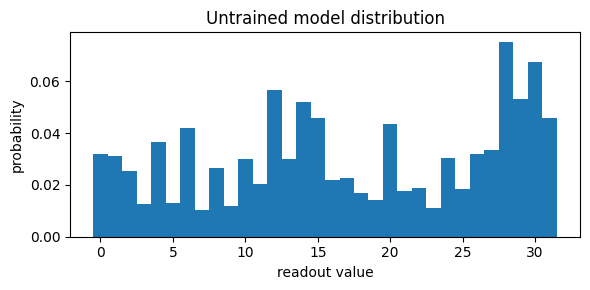

In [4]:
sampler = QiskitSimulator(model)
probs = counts_to_probabilities(
    sampler.exact_output_probabilities(model.params),
    model.num_feature, model.readout_size,
).flatten()

plt.figure(figsize=(6, 3))
plt.bar(np.arange(probs.size), probs, width=1.0)
plt.xlabel('readout value'); plt.ylabel('probability')
plt.title('Untrained model distribution'); plt.tight_layout(); plt.show()

The distribution above does not have any structure because the model is untrained.
The next notebooks fit it to real target densities.

To reload a trained run, use `dqgm.load_parameters(log_dir, run_id, step)`
and assign the result to `model.params`.